# Tabular Playground Series – March 2021
## A complete (but deliberately simple) Kaggle workflow

**Competition:** <https://www.kaggle.com/c/tabular-playground-series-mar-2021>

This notebook walks through every phase of a Kaggle project, **end to end**, and finishes by producing a file you can submit to Kaggle:

1. **Setup & data loading**
2. **Exploratory Data Analysis (EDA)**
3. **Feature engineering**
4. **Classifier** (a baseline and a second model)
5. **Classifier optimisation** (hyperparameter search)
6. **Evaluation** (local validation)
7. **Submission file** → upload to Kaggle and read your score

> ⚠️ This is **not** a competitive solution. Every phase is kept as simple as possible on purpose, so you can see the whole pipeline clearly. Improving it is your job.

**The problem.** Each row is an (anonymised) observation with 19 categorical features (`cat0`–`cat18`) and 11 continuous features (`cont0`–`cont10`). The goal is to predict a binary `target` (0/1).

**The metric.** Submissions are scored with the **area under the ROC curve (AUC)**. AUC measures how well you *rank* positives above negatives, so you must submit a **probability** for `target = 1`, not a hard 0/1 label. (Check the *Evaluation* tab of the competition to confirm.)

## 0. Setup

Before running this notebook:

1. Open the competition page, click **Join Competition / Late Submission** and **accept the rules** (without this, Kaggle will not let you download the data or submit).
2. Download the data (*Data* tab → *Download All*) and unzip it into a `./data/` folder next to this notebook. You should have:
   - `data/train.csv`
   - `data/test.csv`
   - `data/sample_submission.csv`

Alternatively, use the Kaggle API (cell below, optional).

In [4]:
# OPTIONAL: download the data with the Kaggle API.
# Requires your API token in ~/.kaggle/kaggle.json (Kaggle > Settings > API > Create New Token)
# Uncomment to use:
# !pip install -q kaggle
# !kaggle competitions download -c tabular-playground-series-mar-2021 -p data
# !unzip -o -q data/tabular-playground-series-mar-2021.zip -d data

In [5]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
DATA_DIR = Path("data")
pd.set_option("display.max_columns", 40)

## 1. Load the data

In [6]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("train:", train.shape)
print("test: ", test.shape)
print("sample_submission:", sample_submission.shape)
train.head()

train: (300000, 32)
test:  (200000, 31)
sample_submission: (200000, 2)


,id,cat0,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,cat10,cat11,cat12,cat13,cat14,cat15,cat16,cat17,cat18,cont0,cont1,cont2,cont3,cont4,cont5,cont6,cont7,cont8,cont9,cont10,target
0,0,A,I,A,B,B,BI,A,S,Q,A,LO,A,A,A,A,B,D,D,B,0.629858,0.855349,0.759439,0.795549,0.681917,0.621672,0.592184,0.791921,0.815254,0.965006,0.665915,0
1,1,A,I,A,A,E,BI,K,W,AD,F,HJ,A,B,A,B,D,B,D,B,0.370727,0.328929,0.386385,0.541366,0.388982,0.357778,0.600044,0.408701,0.399353,0.927406,0.493729,0
2,2,A,K,A,A,E,BI,A,E,BM,L,DJ,A,B,A,A,B,D,D,B,0.502272,0.322749,0.343255,0.616352,0.793687,0.552877,0.352113,0.388835,0.412303,0.292696,0.549452,0
3,3,A,K,A,C,E,BI,A,Y,AD,F,KV,A,A,A,A,B,D,D,B,0.934242,0.707663,0.831147,0.807807,0.800032,0.619147,0.221789,0.897617,0.633669,0.760318,0.934242,0
4,4,A,I,G,B,E,BI,C,G,Q,A,DP,A,A,A,B,B,B,D,B,0.254427,0.274514,0.338818,0.277308,0.610578,0.128291,0.578764,0.279167,0.351103,0.357084,0.328960,1


In [7]:
# The sample submission tells us EXACTLY what Kaggle expects: column names and number of rows
sample_submission.head()

,id,target
0,5,0.5
1,6,0.5
2,8,0.5
3,9,0.5
4,11,0.5


## 2. Exploratory Data Analysis (EDA)

Questions to answer before modelling:
- What types are the columns? Are there missing values?
- Is the target balanced?
- How many categories does each categorical feature have? Do train and test share the same categories?
- What do the continuous features look like, and do they differ between the two classes?

In [8]:
TARGET = "target"
ID = "id"
cat_cols = [c for c in train.columns if c.startswith("cat")]
cont_cols = [c for c in train.columns if c.startswith("cont")]

print(f"{len(cat_cols)} categorical features:", cat_cols)
print(f"{len(cont_cols)} continuous features:", cont_cols)
print("\nMissing values in train:", int(train.isna().sum().sum()))
print("Missing values in test: ", int(test.isna().sum().sum()))

19 categorical features: ['cat0', 'cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7', 'cat8', 'cat9', 'cat10', 'cat11', 'cat12', 'cat13', 'cat14', 'cat15', 'cat16', 'cat17', 'cat18']
11 continuous features: ['cont0', 'cont1', 'cont2', 'cont3', 'cont4', 'cont5', 'cont6', 'cont7', 'cont8', 'cont9', 'cont10']

Missing values in train: 0
Missing values in test:  0


target
0    220539
1     79461
Name: count, dtype: int64

Share of positives: 26.5%


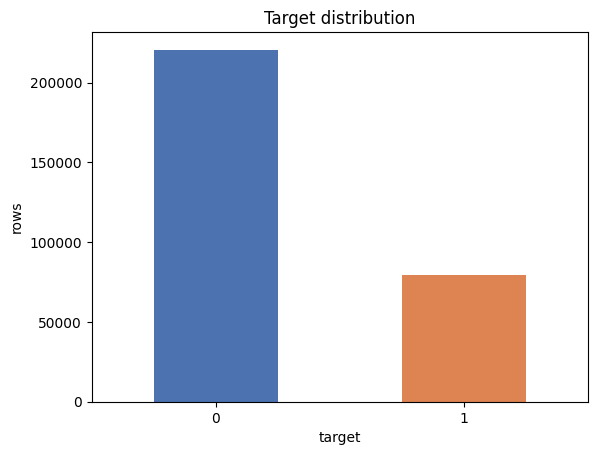

In [9]:
# Target distribution
counts = train[TARGET].value_counts().sort_index()
print(counts)
print("\nShare of positives: {:.1%}".format(train[TARGET].mean()))

counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Target distribution")
plt.xlabel("target"); plt.ylabel("rows"); plt.xticks(rotation=0)
plt.show()

In [10]:
# Cardinality of the categorical features, and categories that appear in test but never in train
card = pd.DataFrame({
    "n_categories_train": train[cat_cols].nunique(),
    "n_categories_test": test[cat_cols].nunique(),
    "unseen_in_train": [len(set(test[c]) - set(train[c])) for c in cat_cols],
})
card

,n_categories_train,n_categories_test,unseen_in_train
cat0,2,2,0
cat1,15,15,0
cat2,19,19,0
cat3,13,13,0
cat4,20,20,0
cat5,84,84,0
cat6,16,16,0
cat7,51,51,0
cat8,61,61,0
cat9,19,19,0


**Note:** one categorical feature has *many* more categories than the others, and some of its categories appear in test but not in train. Our encoders must cope with that (`handle_unknown`).

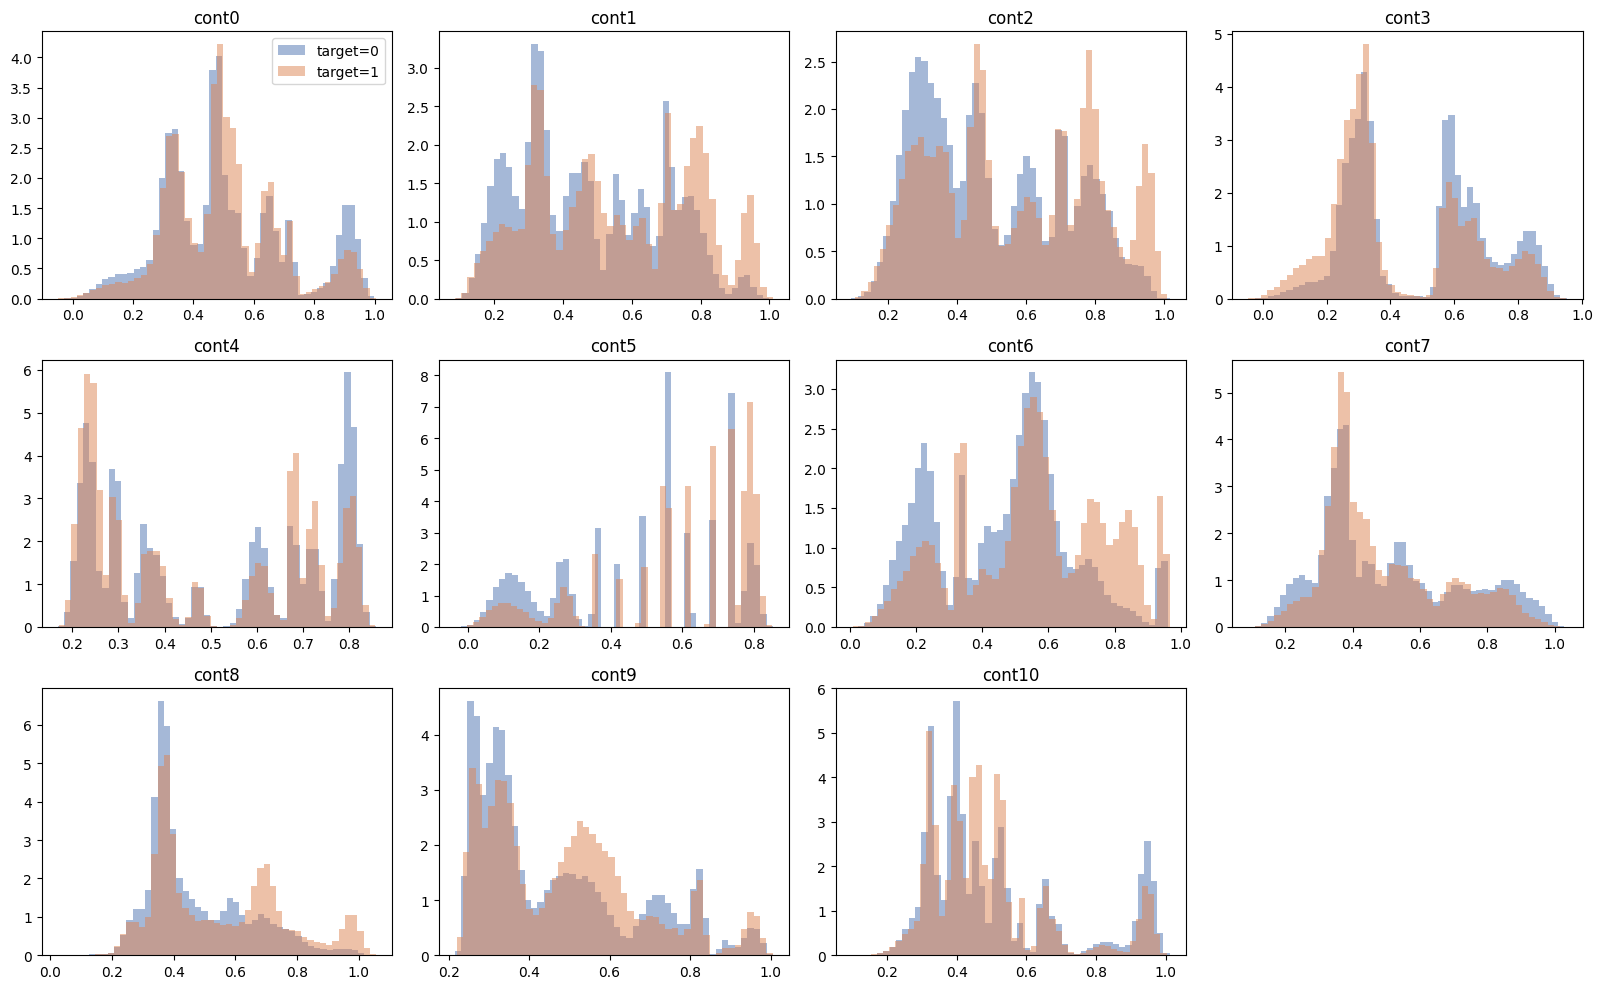

In [11]:
# Continuous features: distribution per class
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), cont_cols):
    for t, color in [(0, "#4C72B0"), (1, "#DD8452")]:
        ax.hist(train.loc[train[TARGET] == t, col], bins=50, alpha=0.5,
                density=True, color=color, label=f"target={t}")
    ax.set_title(col)
axes.ravel()[0].legend()
for ax in axes.ravel()[len(cont_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

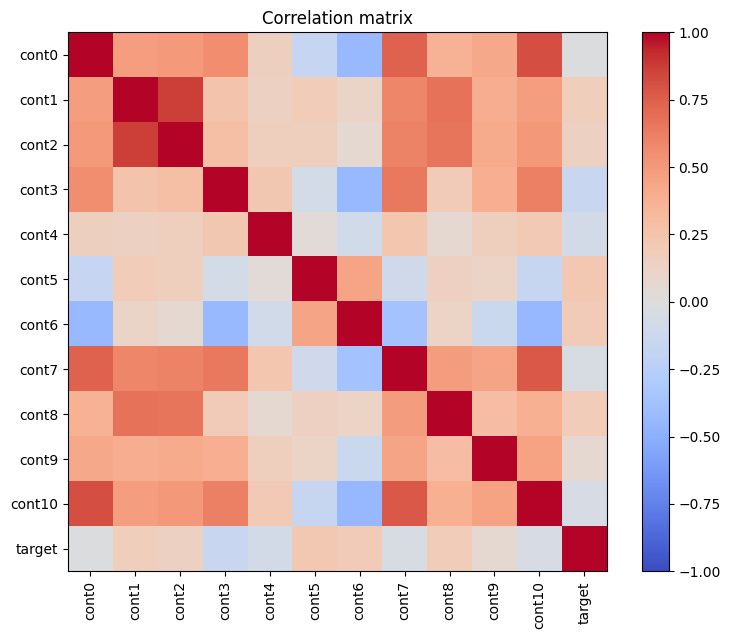

In [12]:
# Correlation between continuous features (and with the target)
corr = train[cont_cols + [TARGET]].corr()
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation matrix")
plt.show()

## 3. Feature engineering

We keep this deliberately minimal — **no new features are created**. We only *encode* the existing ones so the models can use them:

| Model | Categorical features | Continuous features |
|---|---|---|
| Logistic regression | One-hot encoding (rare categories grouped) | Standardised |
| Random forest | Ordinal encoding (one integer per category) | Used as they are |

Everything is wrapped in a scikit-learn `Pipeline`, so the encoders are **fitted on the training data only** (no data leakage).

> 💡 Ideas you could try: frequency encoding, target encoding (inside cross-validation!), interactions between features, removing useless features…

In [13]:
X = train[cat_cols + cont_cols]
y = train[TARGET]
X_test = test[cat_cols + cont_cols]

# Hold out 20% of the training data for local validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train split:", X_tr.shape, " validation split:", X_val.shape)

# Preprocessing for the linear model
linear_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ("num", StandardScaler(), cont_cols),
])

# Preprocessing for tree models
tree_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", cont_cols),
])

train split: (240000, 30)  validation split: (60000, 30)


## 4. Classifier

### 4.1 Baseline: logistic regression
Always start with a simple baseline: it tells you what a "reasonable" score is, and every later model must beat it.

In [14]:
results = {}   # validation AUC of every model we try

t0 = time.time()
logreg = Pipeline([("prep", linear_prep),
                   ("clf", LogisticRegression(max_iter=1000))])
logreg.fit(X_tr, y_tr)
p_val_logreg = logreg.predict_proba(X_val)[:, 1]   # probability of target = 1
results["Logistic regression"] = roc_auc_score(y_val, p_val_logreg)
print(f"Logistic regression  validation AUC = {results['Logistic regression']:.4f}  ({time.time()-t0:.0f}s)")

Logistic regression  validation AUC = 0.8817  (6s)


### 4.2 Random forest (default hyperparameters)

In [15]:
t0 = time.time()
rf = Pipeline([("prep", tree_prep),
               ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                              random_state=RANDOM_STATE))])
rf.fit(X_tr, y_tr)
p_val_rf = rf.predict_proba(X_val)[:, 1]
results["Random forest (default)"] = roc_auc_score(y_val, p_val_rf)
print(f"Random forest        validation AUC = {results['Random forest (default)']:.4f}  ({time.time()-t0:.0f}s)")

Random forest        validation AUC = 0.8830  (12s)


## 5. Classifier optimisation

We tune the random forest with `RandomizedSearchCV`: it tries `n_iter` random combinations from the search space, each evaluated with 3-fold cross-validation using the competition metric (`roc_auc`).

To keep the search fast, it runs on a **random subsample** of the training split. The best combination is then re-trained on the full training split.

> 💡 Number of fits = `n_iter × cv`. Increase `n_iter`, the subsample size or the search space if you have time — or try **Optuna**.

In [16]:
param_distributions = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 10, 15, 20, 30],
    "clf__min_samples_leaf": [1, 5, 20, 50],
    "clf__max_features": ["sqrt", 0.3, 0.5],
}

SEARCH_ROWS = 30_000   # subsample used for the search
X_search, _, y_search, _ = train_test_split(
    X_tr, y_tr, train_size=SEARCH_ROWS, stratify=y_tr, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    estimator=Pipeline([("prep", tree_prep),
                        ("clf", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
    param_distributions=param_distributions,
    n_iter=8,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    verbose=1,
)

t0 = time.time()
search.fit(X_search, y_search)
print(f"Search took {time.time()-t0:.0f}s")
print("Best CV AUC (on the subsample):", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Search took 26s
Best CV AUC (on the subsample): 0.8772
Best parameters: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


In [17]:
# All tried combinations, best first
cv_results = pd.DataFrame(search.cv_results_)
cv_results[["params", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)

,params,mean_test_score,std_test_score
2,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.877172,0.004606
6,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.876364,0.005290
4,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.875924,0.004651
3,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.875572,0.004648
7,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.875042,0.005066
0,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.874280,0.004810
1,"{'clf__n_estimators': 200, 'clf__min_samples_l...",0.873334,0.004876
5,"{'clf__n_estimators': 100, 'clf__min_samples_l...",0.871403,0.005318


In [18]:
# Re-train the best configuration on the full training split
t0 = time.time()
rf_best = search.best_estimator_
rf_best.fit(X_tr, y_tr)
p_val_best = rf_best.predict_proba(X_val)[:, 1]
results["Random forest (tuned)"] = roc_auc_score(y_val, p_val_best)
print(f"Tuned random forest  validation AUC = {results['Random forest (tuned)']:.4f}  ({time.time()-t0:.0f}s)")

Tuned random forest  validation AUC = 0.8864  (12s)


## 6. Evaluation

We compare all models on the **same validation split** with the **competition metric (AUC)**. This local score is our estimate of what Kaggle will report.

In [19]:
summary = pd.Series(results, name="validation AUC").sort_values(ascending=False).to_frame()
summary

,validation AUC
Random forest (tuned),0.886364
Random forest (default),0.883014
Logistic regression,0.881745


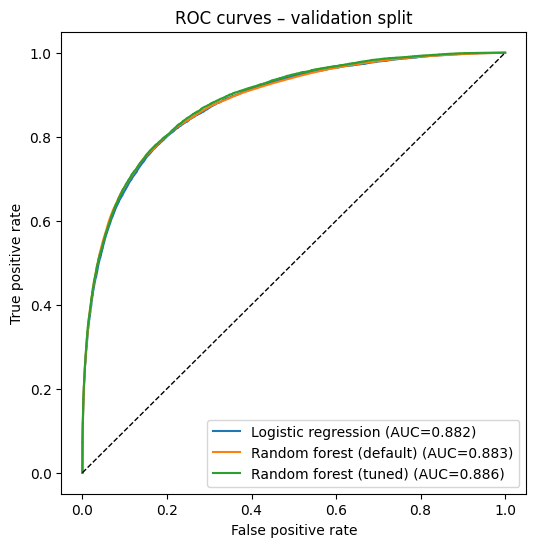

In [20]:
# ROC curves on the validation split
plt.figure(figsize=(6, 6))
for name, p in [("Logistic regression", p_val_logreg),
                ("Random forest (default)", p_val_rf),
                ("Random forest (tuned)", p_val_best)]:
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves – validation split"); plt.legend(loc="lower right")
plt.show()

Accuracy at threshold 0.5: 0.8457
AUC using hard 0/1 labels: 0.7645  vs AUC using probabilities: 0.8864

              precision    recall  f1-score   support

           0      0.864     0.937     0.899     44108
           1      0.772     0.592     0.670     15892

    accuracy                          0.846     60000
   macro avg      0.818     0.765     0.785     60000
weighted avg      0.840     0.846     0.839     60000



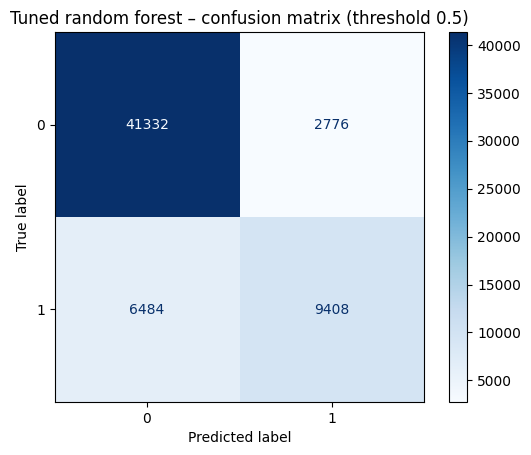

In [21]:
# Hard labels (threshold 0.5) — useful to read, but NOT what Kaggle scores
y_pred_best = (p_val_best >= 0.5).astype(int)
print("Accuracy at threshold 0.5:", round(accuracy_score(y_val, y_pred_best), 4))
print("AUC using hard 0/1 labels:", round(roc_auc_score(y_val, y_pred_best), 4),
      " vs AUC using probabilities:", round(results["Random forest (tuned)"], 4))
print()
print(classification_report(y_val, y_pred_best, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_val, y_pred_best)).plot(cmap="Blues")
plt.title("Tuned random forest – confusion matrix (threshold 0.5)")
plt.show()

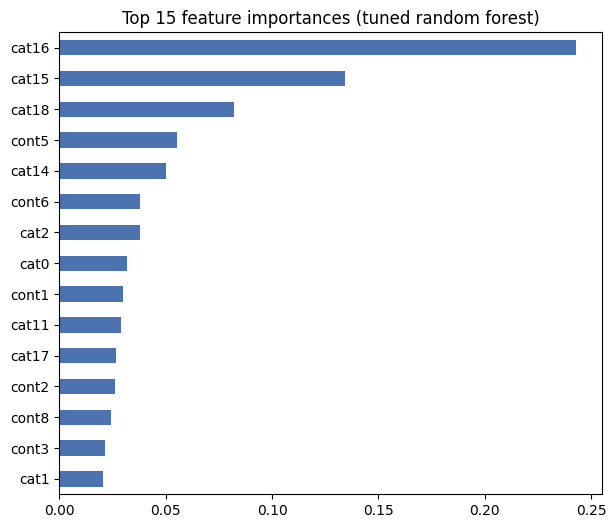

In [22]:
# Which features does the tuned forest rely on?
importances = pd.Series(rf_best.named_steps["clf"].feature_importances_,
                        index=cat_cols + cont_cols).sort_values()
importances.tail(15).plot(kind="barh", figsize=(7, 6), color="#4C72B0")
plt.title("Top 15 feature importances (tuned random forest)")
plt.show()

## 7. Create the submission file

1. Re-train the chosen model on **all** the training data (train + validation).
2. Predict the **probability** of `target = 1` for every row of `test.csv`.
3. Save a CSV with exactly the same columns and number of rows as `sample_submission.csv`.

In [23]:
final_model = rf_best          # choose the model you want to submit
t0 = time.time()
final_model.fit(X, y)
test_proba = final_model.predict_proba(X_test)[:, 1]
print(f"Final model trained and predicted in {time.time()-t0:.0f}s")

submission = pd.DataFrame({ID: test[ID], TARGET: test_proba})

# --- Sanity checks: a wrong format is the most common reason for a failed submission ---
assert list(submission.columns) == list(sample_submission.columns), "column names differ"
assert len(submission) == len(sample_submission), "wrong number of rows"
assert submission[ID].is_unique, "duplicated ids"
assert submission[TARGET].between(0, 1).all(), "predictions must be probabilities in [0, 1]"

submission.to_csv("submission.csv", index=False)
print("Saved submission.csv", submission.shape)
submission.head()

Final model trained and predicted in 15s
Saved submission.csv (200000, 2)


,id,target
0,5,0.134422
1,6,0.492671
2,8,0.036206
3,9,0.145116
4,11,0.132255


In [24]:
# For the experiment in the homework: the SAME model, but submitting hard 0/1 labels
submission_labels = submission.copy()
submission_labels[TARGET] = (test_proba >= 0.5).astype(int)
submission_labels.to_csv("submission_labels.csv", index=False)
print("Saved submission_labels.csv")

Saved submission_labels.csv


## 8. Submit to Kaggle and find your score

**Option A – website**
1. Go to the competition page and click **Late Submission** (the competition is closed, but late submissions are still scored).
2. Upload `submission.csv`, write a short description (e.g. *"tuned random forest, notebook as provided"*) and click **Submit**.
3. Wait a few seconds, then open the **Submissions** tab: your entry shows a **Public Score** and a **Private Score**.
4. Take a **screenshot** — it is part of your deliverable.

Late submissions do **not** appear on the leaderboard: compare your private score with the **Leaderboard → Private** tab yourself to see where you would have ranked.

**Option B – Kaggle API** (cell below)

In [25]:
# OPTIONAL: submit and read the score with the Kaggle API
# !kaggle competitions submit -c tabular-playground-series-mar-2021 -f submission.csv -m "Tuned random forest"
# !kaggle competitions submissions -c tabular-playground-series-mar-2021

## 9. Record your results

| Submission | File | Validation AUC (this notebook) | Kaggle public | Kaggle private |
|---|---|---|---|---|
| 1. Notebook as provided | `submission.csv` | | | |
| 2. Hard labels instead of probabilities | `submission_labels.csv` | | | |
| 3. Your improved model | | | | |
| 4. Your best attempt | | | | |